<div align="center">

# МГТУ им. Н.Э. Баумана

### Факультет «Информатика и системы управления» (ИУ)
### Кафедра «Информационные системы и телекоммуникации» (ИУ3)

# Отчёт по лабораторной работе №5
## по курсу «Технологии машинного обучения»

### Тема: Ансамбли моделей машинного обучения. Часть 1

</div>

---

**Выполнил:** Суржиков Лев Алексеевич

**Группа:** ИУ3С-51Б

**Проверил:** Ю.Е. Гапанюк

---


## 1. Описание задания

**Цель работы:** изучение ансамблей моделей машинного обучения.

**Задание:**
1. Выбрать набор данных для решения задачи классификации или регрессии.
2. В случае необходимости провести удаление или заполнение пропусков и кодирование категориальных признаков.
3. С использованием метода train_test_split разделить выборку на обучающую и тестовую.
4. Обучить ансамблевые модели: две модели группы бэггинга (бэггинг, случайный лес или сверхслучайные деревья), AdaBoost, градиентный бустинг.
5. Оценить качество моделей с помощью одной из подходящих для задачи метрик. Сравнить качество полученных моделей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import warnings

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

matplotlib.rcParams["font.family"] = "DejaVu Sans"
matplotlib.rcParams["axes.unicode_minus"] = False
warnings.filterwarnings("ignore", category=RuntimeWarning)  # лишние предупреждения numpy на macOS

BLUE_DARK = "#1B3B6F"
BLUE = "#3B6EA5"
BLUE_LIGHT = "#8FB8D9"
RED_DARK = "#7A1F2B"
RED = "#B23A48"
RED_LIGHT = "#E0949C"

## 2. Набор данных

Используется тот же финансовый датасет, что и в ЛР2–ЛР4, — **Loan Prediction Problem Dataset** (заявки на кредит, https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset). Решается задача **бинарной классификации**: предсказать `Loan_Status` — одобрят ли кредит (1) или откажут (0).

In [2]:
df = pd.read_csv("loan_prediction.csv")
print("Размер:", df.shape)
print(df["Loan_Status"].value_counts())
df.head()


Размер: (614, 13)
Loan_Status
Y    422
N    192
Name: count, dtype: int64


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## 3. Предобработка данных

Пропуски заполняем медианой и модой, категориальные признаки кодируем (так же, как в ЛР2 и ЛР4).

In [3]:
data = df.drop(columns=["Loan_ID"])

data[["LoanAmount"]] = SimpleImputer(strategy="median").fit_transform(data[["LoanAmount"]])
mode_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Loan_Amount_Term", "Credit_History"]
data[mode_cols] = SimpleImputer(strategy="most_frequent").fit_transform(data[mode_cols])

for col in ["Gender", "Married", "Education", "Self_Employed", "Loan_Status"]:
    data[col] = LabelEncoder().fit_transform(data[col])
data["Dependents"] = OrdinalEncoder(categories=[["0", "1", "2", "3+"]]).fit_transform(data[["Dependents"]])
data = pd.get_dummies(data, columns=["Property_Area"], prefix="Area", dtype=int)
data = data.astype(float)

print("Пропусков:", data.isnull().sum().sum())
data.head()


Пропусков: 0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Area_Rural,Area_Semiurban,Area_Urban
0,1.0,0.0,0.0,0.0,0.0,5849.0,0.0,128.0,360.0,1.0,1.0,0.0,0.0,1.0
1,1.0,1.0,1.0,0.0,0.0,4583.0,1508.0,128.0,360.0,1.0,0.0,1.0,0.0,0.0
2,1.0,1.0,0.0,0.0,1.0,3000.0,0.0,66.0,360.0,1.0,1.0,0.0,0.0,1.0
3,1.0,1.0,0.0,1.0,0.0,2583.0,2358.0,120.0,360.0,1.0,1.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,6000.0,0.0,141.0,360.0,1.0,1.0,0.0,0.0,1.0


## 4. Разделение на обучающую и тестовую выборки

Ансамбли строятся на деревьях решений, поэтому масштабировать признаки не нужно.

In [4]:
X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)
print("Обучающая выборка:", X_train.shape, " Тестовая выборка:", X_test.shape)

Обучающая выборка: (460, 13)  Тестовая выборка: (154, 13)


## 5. Обучение моделей

Основная метрика — **F1-мера** (учитывает precision и recall, подходит при несбалансированных классах: одобренных заявок примерно в 2 раза больше). Дополнительно выводим accuracy и ROC-AUC.

Для сравнения сначала обучим одно дерево решений без ограничения глубины — именно такие деревья используются внутри ансамблей.

In [5]:
results = {}

def evaluate(name, model):
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    results[name] = {
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, score),
    }
    print(name)
    print("  Accuracy на обучающей:", round(accuracy_score(y_train, model.predict(X_train)), 4))
    for k, v in results[name].items():
        print(f"  {k:9} {v:.4f}")
    return pred

tree = DecisionTreeClassifier(random_state=1)
tree.fit(X_train, y_train)
pred_tree = evaluate("Одно дерево решений", tree)

Одно дерево решений
  Accuracy на обучающей: 1.0
  F1        0.8186
  Accuracy  0.7468
  ROC-AUC   0.6963


### 5.1. Бэггинг

Бэггинг обучает много деревьев на бутстреп-выборках (случайный выбор строк с возвращением) и усредняет их ответы (голосование).

In [6]:
bagging = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                            oob_score=True, random_state=1)
bagging.fit(X_train, y_train)
print("OOB-оценка accuracy:", round(bagging.oob_score_, 4))
pred_bag = evaluate("Бэггинг", bagging)

OOB-оценка accuracy: 0.7609
Бэггинг
  Accuracy на обучающей: 1.0
  F1        0.8596
  Accuracy  0.7922
  ROC-AUC   0.7650


### 5.2. Случайный лес

Случайный лес — бэггинг над деревьями, где при каждом разбиении узла дерево выбирает лучший признак только из случайного подмножества признаков. Поэтому деревья получаются менее похожими друг на друга.

In [7]:
forest = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=1)
forest.fit(X_train, y_train)
print("OOB-оценка accuracy:", round(forest.oob_score_, 4))
pred_rf = evaluate("Случайный лес", forest)

OOB-оценка accuracy: 0.7739
Случайный лес
  Accuracy на обучающей: 1.0
  F1        0.8658
  Accuracy  0.7987
  ROC-AUC   0.7704


In [8]:
# без ограничения глубины лес запоминает обучающую выборку,
# поэтому подберём max_depth кросс-валидацией на обучающей выборке (как в ЛР3)
cv_f1 = {}
for d in [2, 3, 4, 5, 7, 10, None]:
    rf = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=1)
    cv_f1[d] = cross_val_score(rf, X_train, y_train, cv=5, scoring="f1").mean()
    print(f"max_depth={str(d):5}  F1 на кросс-валидации = {cv_f1[d]:.4f}")

best_depth = max(cv_f1, key=cv_f1.get)
print("Лучшая глубина:", best_depth)

max_depth=2      F1 на кросс-валидации = 0.8537


max_depth=3      F1 на кросс-валидации = 0.8713


max_depth=4      F1 на кросс-валидации = 0.8747


max_depth=5      F1 на кросс-валидации = 0.8729


max_depth=7      F1 на кросс-валидации = 0.8720


max_depth=10     F1 на кросс-валидации = 0.8638


max_depth=None   F1 на кросс-валидации = 0.8564
Лучшая глубина: 4


In [9]:
forest_best = RandomForestClassifier(n_estimators=100, max_depth=best_depth, random_state=1)
forest_best.fit(X_train, y_train)
pred_rf_best = evaluate(f"Случайный лес (max_depth = {best_depth})", forest_best)

Случайный лес (max_depth = 4)
  Accuracy на обучающей: 0.8152
  F1        0.8870
  Accuracy  0.8247
  ROC-AUC   0.7562


### 5.3. AdaBoost

AdaBoost обучает слабые модели (по умолчанию «пни» — деревья глубины 1) последовательно: каждая следующая модель больше внимания уделяет объектам, на которых ошиблись предыдущие.

In [10]:
ada = AdaBoostClassifier(n_estimators=100, random_state=1)
ada.fit(X_train, y_train)
pred_ada = evaluate("AdaBoost", ada)

AdaBoost
  Accuracy на обучающей: 0.8152
  F1        0.8908
  Accuracy  0.8312
  ROC-AUC   0.7501


### 5.4. Градиентный бустинг

Градиентный бустинг тоже строит деревья последовательно, но каждое новое дерево обучается на ошибках (антиградиенте функции потерь) текущего ансамбля.

In [11]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=1)
gb.fit(X_train, y_train)
pred_gb = evaluate("Градиентный бустинг", gb)

Градиентный бустинг
  Accuracy на обучающей: 0.8978
  F1        0.8707
  Accuracy  0.8052
  ROC-AUC   0.7258


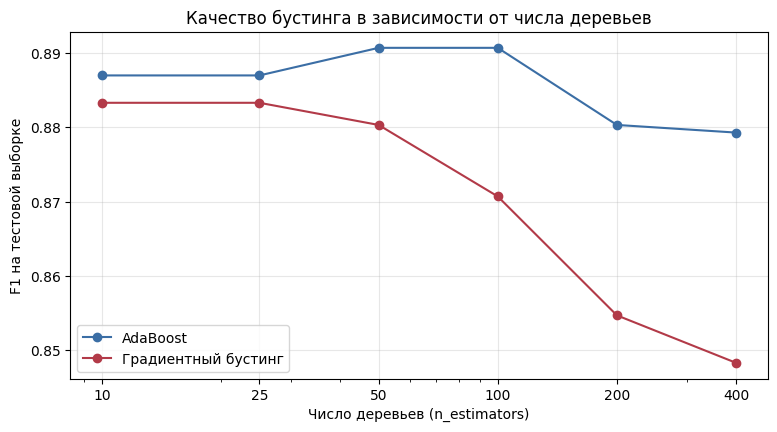

In [12]:
# как качество бустинга зависит от числа деревьев
n_list = [10, 25, 50, 100, 200, 400]
ada_f1, gb_f1 = [], []
for n in n_list:
    ada_f1.append(f1_score(y_test, AdaBoostClassifier(n_estimators=n, random_state=1)
                           .fit(X_train, y_train).predict(X_test)))
    gb_f1.append(f1_score(y_test, GradientBoostingClassifier(n_estimators=n, random_state=1)
                          .fit(X_train, y_train).predict(X_test)))

plt.figure(figsize=(9, 4.5))
plt.plot(n_list, ada_f1, marker="o", color=BLUE, label="AdaBoost")
plt.plot(n_list, gb_f1, marker="o", color=RED, label="Градиентный бустинг")
plt.xscale("log")
plt.xticks(n_list, n_list)
plt.xlabel("Число деревьев (n_estimators)")
plt.ylabel("F1 на тестовой выборке")
plt.title("Качество бустинга в зависимости от числа деревьев")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Сравнение качества моделей

In [13]:
compare = pd.DataFrame(results).T.round(4).sort_values("F1", ascending=False)
compare

,F1,Accuracy,ROC-AUC
AdaBoost,0.8908,0.8312,0.7501
Случайный лес (max_depth = 4),0.8870,0.8247,0.7562
Градиентный бустинг,0.8707,0.8052,0.7258
Случайный лес,0.8658,0.7987,0.7704
Бэггинг,0.8596,0.7922,0.7650
Одно дерево решений,0.8186,0.7468,0.6963


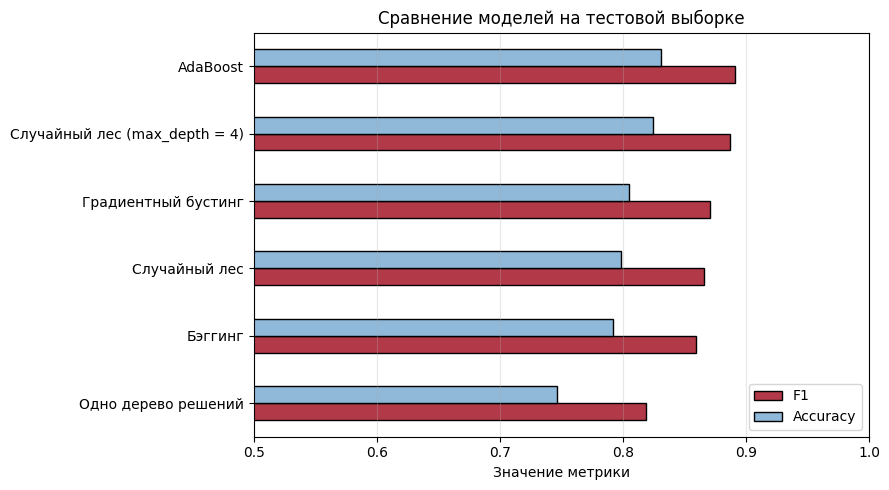

In [14]:
ax = compare[["F1", "Accuracy"]].sort_values("F1").plot(kind="barh", figsize=(9, 5),
                                                    color=[RED, BLUE_LIGHT], edgecolor="black")
plt.title("Сравнение моделей на тестовой выборке")
plt.xlabel("Значение метрики")
plt.xlim(0.5, 1)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

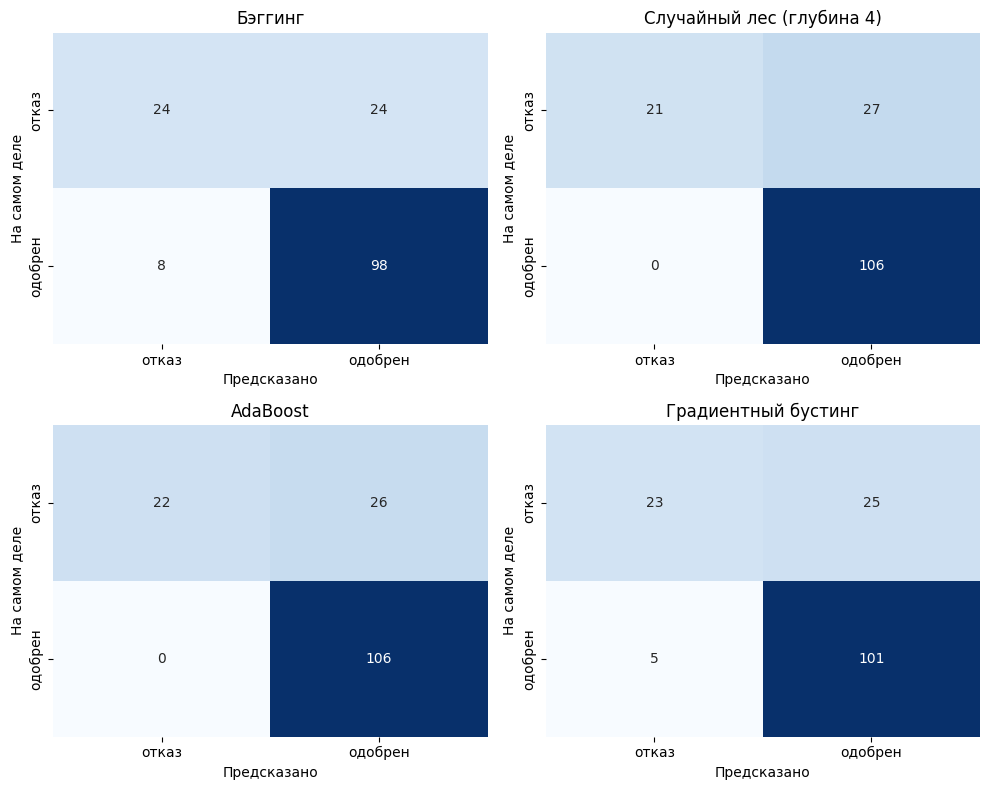

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (title, pred) in zip(axes.ravel(), [("Бэггинг", pred_bag), (f"Случайный лес (глубина {best_depth})", pred_rf_best),
                                     ("AdaBoost", pred_ada), ("Градиентный бустинг", pred_gb)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["отказ", "одобрен"], yticklabels=["отказ", "одобрен"])
    ax.set_title(title)
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("На самом деле")
plt.tight_layout()
plt.show()

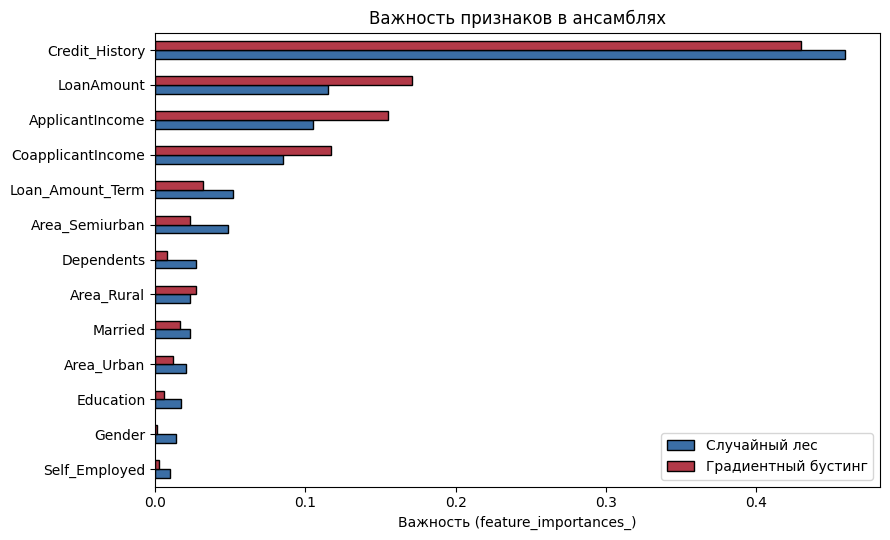

,Случайный лес,Градиентный бустинг
Credit_History,0.4595,0.4296
LoanAmount,0.1149,0.1710
ApplicantIncome,0.1051,0.1548
CoapplicantIncome,0.0849,0.1168
Loan_Amount_Term,0.0520,0.0319
Area_Semiurban,0.0482,0.0231
Dependents,0.0275,0.0079
Area_Rural,0.0230,0.0272
Married,0.0230,0.0163
Area_Urban,0.0207,0.0120


In [16]:
# какие признаки важны для ансамблей
imp = pd.DataFrame({"Случайный лес": forest_best.feature_importances_,
                    "Градиентный бустинг": gb.feature_importances_}, index=X.columns).sort_values("Случайный лес")
imp.plot(kind="barh", figsize=(9, 5.5), color=[BLUE, RED], edgecolor="black")
plt.title("Важность признаков в ансамблях")
plt.xlabel("Важность (feature_importances_)")
plt.tight_layout()
plt.show()
imp.sort_values("Случайный лес", ascending=False).round(4)

## 7. Выводы

1. Для задачи бинарной классификации (одобрение кредита) использован датасет Loan Prediction: пропуски заполнены, категориальные признаки закодированы, выборка разделена на обучающую и тестовую (75/25, со стратификацией).
2. Обучены четыре ансамбля по 100 деревьев: бэггинг и случайный лес (группа бэггинга), AdaBoost и градиентный бустинг. Основная метрика — F1-мера, дополнительно accuracy и ROC-AUC.
3. Все ансамбли лучше одного дерева решений (F1 0,819, accuracy 0,747): даже простой бэггинг поднимает F1 до 0,860, а случайный лес — до 0,866, потому что усреднение многих деревьев уменьшает переобучение.
4. Лучший результат на тестовой выборке у AdaBoost (F1 0,891, accuracy 0,831). Почти не уступает случайный лес с глубиной деревьев 4, подобранной кросс-валидацией (F1 0,887, accuracy 0,825). Градиентный бустинг немного переобучился (accuracy 0,898 на обучающей и 0,805 на тестовой выборке), F1 0,871. По ROC-AUC лучший — случайный лес без ограничения глубины (0,770).
5. Во всех ансамблях самый важный признак — Credit_History (важность около 0,43–0,46), затем сумма кредита и доходы заёмщика и созаёмщика. Лучшие ансамбли дали такое же качество, как лучший SVM из ЛР4 (F1 0,891): датасет небольшой (614 заявок), и основную часть информации несёт один признак — кредитная история.